# 04 — Vented Box Design: Matching a Reference Max-SPL Curve

The goal is to size a vented box for a given driver. The design is judged by its **maximum SPL curve**: the loudest the system can play at each frequency without exceeding the cone's $X_{max}$ or the driver's thermal limit. The voltage is therefore not fixed.

The notebook follows these steps:

1. The max-SPL curve of a given box
2. A least-squares error against a reference over a band, and its landscape over (volume, tuning frequency)
3. The best tuning for each volume, and the sealed-box baseline
4. The smallest volume that meets an error tolerance
5. A check of the derived design with the real `VentedBox`
6. A smaller box: limits on $f_b$ and $f_3$ and a drive-voltage cap, compared with a small sealed box

At fixed volume $V$ and tuning $f_b$, the acoustic response does not depend on the vent area. The optimisation is therefore over $(V, f_b)$ only. The vent radius $a_v$ and length $T$ follow from a port-speed limit and from $f_b$.

In [25]:
import sys
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")

from src.constants import AIR
from src.components.driver import Driver
from src.components.enclosure import VentedBox
from src.components.radiation import MonopoleRadiation
from src.system import LoudspeakerSystem
from src.optimization import (
    DesignLimits,
    make_grid,
    max_spl_curve,
    vented_system,
    sealed_system,
    spl_error,
    f3_frequency,
    best_tuning,
    volume_sweep,
    error_grid,
)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## Setup

- **Driver:** the same one used in notebooks 01 and 03.
- **Frequency grid:** log-spaced, so every octave carries the same weight in the error.
- **Reference:** a flat curve over the band. In `"shape"` mode only its shape matters: the best constant level offset is removed, which has a closed form. The other modes are `"level"` (compare directly) and `"shortfall"` (only SPL below the reference counts).
- **Limits:**
  - `vent_velocity`: the peak vent air speed on the max-SPL drive curve.
  - `max_vent_length`: the physical vent length $T$.
  - `min_vent_radius`: the smallest vent radius allowed.
- **Leakage:** $Q_L$ is fixed.

In [26]:
driver = Driver.from_thiele_small(
    Re=3.4,
    Le=1.43e-3,
    Fs=35.7,
    Qms=6.620,
    Qes=0.360,
    Vas=12.10e-3,
    Sd=124.7e-4,
    Xmax=6e-3,
    Pe=100,
)

freqs = make_grid(10, 1000, 300)
band = (30, 200)          # Hz, matching band
reference_db = 0.0        # flat reference; only its shape matters in "shape" mode
mode = "shape"
limits = DesignLimits(vent_velocity=17.0, max_vent_length=0.40, min_vent_radius=0.015)
Ql = 7.0
distance = 1.0

settings = dict(
    freqs=freqs,
    band=band,
    reference_db=reference_db,
    mode=mode,
    limits=limits,
    Ql=Ql,
    distance=distance,
)
in_band = (freqs >= band[0]) & (freqs <= band[1])

print(f"Thermal voltage limit:  {np.sqrt(driver.Pe * driver.Re):.1f} V RMS")
print(f"Xmax:                   {1e3 * driver.Xmax:.1f} mm peak = {1e3 * driver.Xmax / np.sqrt(2):.2f} mm RMS")

Thermal voltage limit:  18.4 V RMS
Xmax:                   6.0 mm peak = 4.24 mm RMS


# Step 1 — The max-SPL curve

The model is linear, so a single solve at 1 V gives $\hat p(f)$, $\hat X_d(f)$ and $\hat Q_v(f)$ for every drive level. The largest RMS drive voltage allowed at each frequency is

$$V_{op}(f) = \min\left(\frac{X_{max}/\sqrt{2}}{|\hat X_d(f)|},\ \sqrt{P_e R_e}\right)$$

and the max-SPL curve is

$$\mathrm{SPL}_{max}(f) = 20\log_{10}\frac{|\hat p(f)|\,V_{op}(f)}{p_{ref}}$$

Phasors are RMS while $X_{max}$ is a peak value, which explains the $\sqrt{2}$.

The thermal limit $\sqrt{P_e R_e}$ is needed: excursion is smallest near $f_b$, so the excursion limit alone would allow unbounded voltage there.

Below, a box of 20 L tuned to 38 Hz (the box from notebook 03) is compared with a sealed box of the same volume.

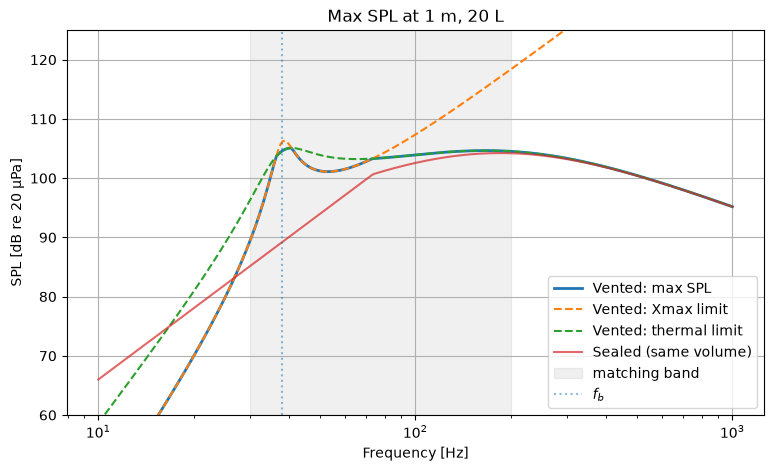

RMS shape error, vented: 2.84 dB
RMS shape error, sealed: 6.00 dB


In [27]:
volume = 20e-3    # m^3
fb_example = 38.0 # Hz

vented_curve = max_spl_curve(vented_system(driver, volume, fb_example, Ql=Ql), freqs, distance)
sealed_curve = max_spl_curve(sealed_system(driver, volume), freqs, distance)

plt.figure()
plt.semilogx(freqs, vented_curve.spl, linewidth=2, label="Vented: max SPL")
plt.semilogx(freqs, vented_curve.spl_excursion_limited, "--", label="Vented: Xmax limit")
plt.semilogx(freqs, vented_curve.spl_voltage_limited, "--", label="Vented: thermal limit")
plt.semilogx(freqs, sealed_curve.spl, alpha=0.7, label="Sealed (same volume)")
plt.axvspan(*band, color="k", alpha=0.06, label="matching band")
plt.axvline(fb_example, linestyle=":", alpha=0.5, label="$f_b$")
plt.ylim(60, 125)
plt.xlabel("Frequency [Hz]")
plt.ylabel("SPL [dB re 20 µPa]")
plt.title(f"Max SPL at {distance:.0f} m, {1e3 * volume:.0f} L")
plt.legend()
plt.show()

for label, curve in (("vented", vented_curve), ("sealed", sealed_curve)):
    print(f"RMS shape error, {label}: {spl_error(curve.spl[in_band], reference_db, 'shape'):.2f} dB")

## Vent size does not change the curve

The acoustic response depends on $V$ and $f_b$ only: $C_{ab}$, $M_{ap}$ and the leakage resistance do not depend on the vent area at fixed $f_b$, and $Q_v$ does not depend on it either. The check below builds real `VentedBox` objects with very different vent radii, each with its length solved for the same $f_b$.

In [28]:
for radius in (0.015, 0.03, 0.06):
    area = np.pi * radius**2
    effective_length = AIR.speed_of_sound**2 * area / ((2 * np.pi * fb_example)**2 * volume)
    box = VentedBox(volume, radius, effective_length - 8 * radius / (3 * np.pi), Ql=Ql)
    curve = max_spl_curve(LoudspeakerSystem(driver, box, radiation=MonopoleRadiation()), freqs, distance)

    print(
        f"radius {1e2 * radius:4.1f} cm, length {1e2 * box.vent_length:5.1f} cm: "
        f"max |SPL difference| = {np.max(np.abs(curve.spl - vented_curve.spl)):.1e} dB"
    )

radius  1.5 cm, length   6.0 cm: max |SPL difference| = 0.0e+00 dB
radius  3.0 cm, length  26.7 cm: max |SPL difference| = 0.0e+00 dB
radius  6.0 cm, length 112.1 cm: max |SPL difference| = 0.0e+00 dB


# Step 2 — Error landscape over $(V, f_b)$

The error is the RMS difference in dB between the max-SPL curve and the reference over the band:

$$E = \sqrt{\frac{1}{N}\sum_i\left(\mathrm{SPL}_{max}(f_i)-\mathrm{SPL}_{ref}(f_i)-c\right)^2}$$

where $c$ is the mean difference in `"shape"` mode.

The vent follows from the port-speed limit. The vent volume flow on the max-SPL curve is independent of the vent area, so

$$S_{v,min} = \frac{\max_f |\hat Q_v(f)|\,V_{op}(f)}{U_{lim}}$$

The length $T$ then follows from $f_b$. Designs with $T > T_{max}$ or $T \le 0$ are infeasible and are shaded grey.

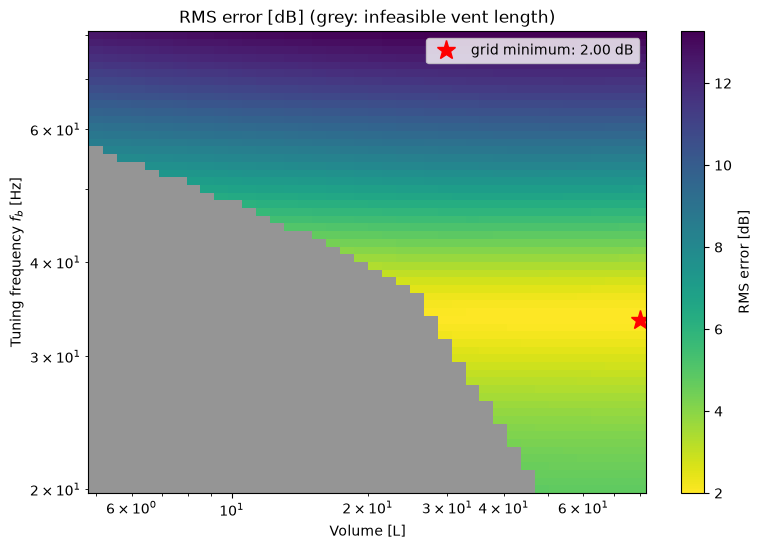

In [29]:
volumes = np.geomspace(5e-3, 80e-3, 40)
fbs = np.geomspace(20, 80, 60)

error, feasible, _ = error_grid(driver, volumes, fbs, **settings)
feasible_error = np.where(feasible, error, np.nan)

fig, ax = plt.subplots(figsize=(9, 6))
mesh = ax.pcolormesh(1e3 * volumes, fbs, feasible_error.T, shading="auto", cmap="viridis_r")
ax.pcolormesh(1e3 * volumes, fbs, np.where(feasible, np.nan, 1.0).T, shading="auto", cmap="Greys", vmin=0, vmax=2)

i, j = np.unravel_index(np.nanargmin(feasible_error), feasible_error.shape)
ax.plot(1e3 * volumes[i], fbs[j], "r*", markersize=14, label=f"grid minimum: {feasible_error[i, j]:.2f} dB")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Volume [L]")
ax.set_ylabel("Tuning frequency $f_b$ [Hz]")
ax.set_title("RMS error [dB] (grey: infeasible vent length)")
ax.grid(False)
ax.legend()
fig.colorbar(mesh, label="RMS error [dB]")
plt.show()

# Step 3 — Best tuning for each volume

For every volume, `best_tuning` scans $f_b$ on a coarse grid and refines the best cell with a bounded 1D minimisation. The result is the smallest achievable error as a function of volume, with the sealed box as a baseline. The sealed box has no tuning to optimise, so only its error at each volume is shown.

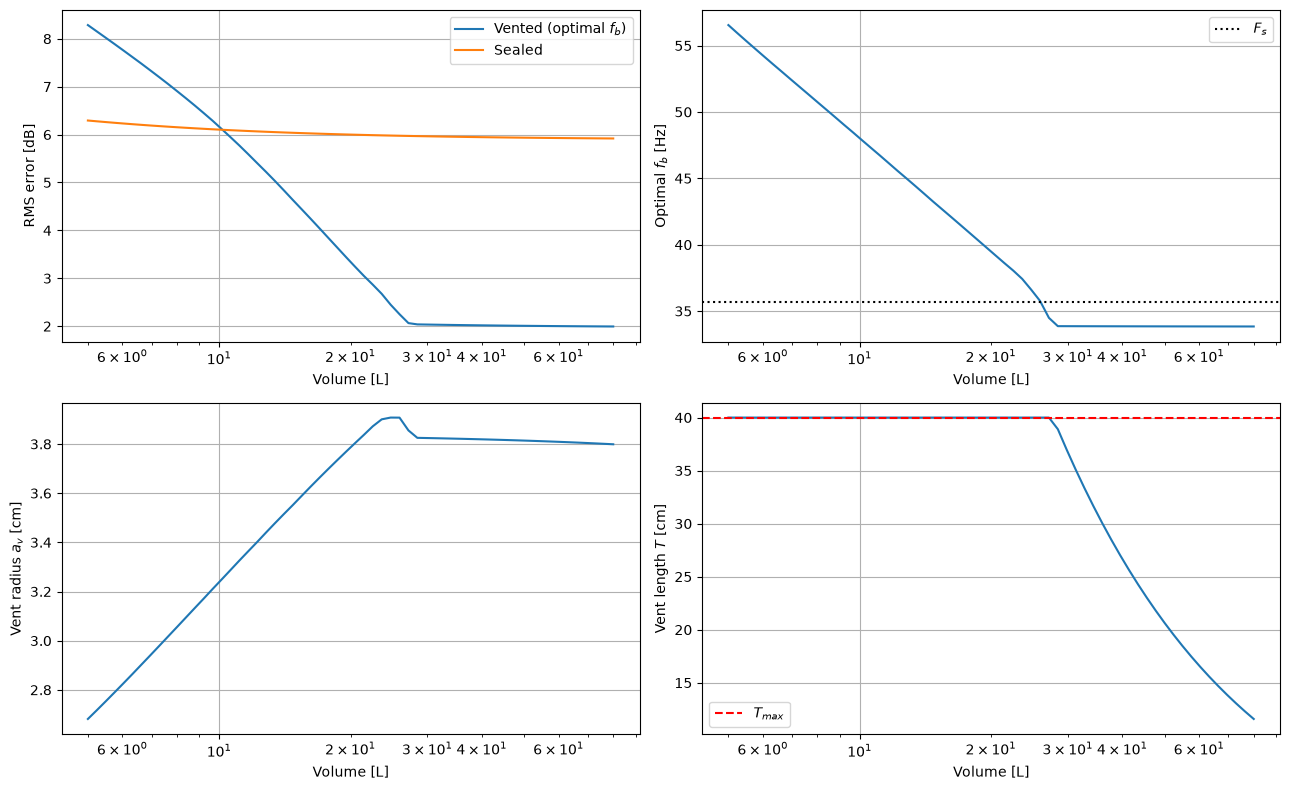

In [30]:
sweep_volumes = np.geomspace(5e-3, 80e-3, 60)
sweep = volume_sweep(driver, sweep_volumes, **settings)

designs = [design for design in sweep if design is not None]
v = np.array([design.volume for design in designs])
error_opt = np.array([design.error for design in designs])
fb_opt = np.array([design.fb for design in designs])
radius_opt = np.array([design.vent.vent_radius for design in designs])
length_opt = np.array([design.vent.vent_length for design in designs])

sealed_error = np.array([
    spl_error(max_spl_curve(sealed_system(driver, volume_i), freqs, distance).spl[in_band], reference_db, mode)
    for volume_i in sweep_volumes
])

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].semilogx(1e3 * v, error_opt, label="Vented (optimal $f_b$)")
axes[0, 0].semilogx(1e3 * sweep_volumes, sealed_error, label="Sealed")
axes[0, 0].set_ylabel("RMS error [dB]")
axes[0, 0].legend()

axes[0, 1].semilogx(1e3 * v, fb_opt)
axes[0, 1].axhline(driver.Fs, color="k", linestyle=":", label="$F_s$")
axes[0, 1].set_ylabel("Optimal $f_b$ [Hz]")
axes[0, 1].legend()

axes[1, 0].semilogx(1e3 * v, 1e2 * radius_opt)
axes[1, 0].set_ylabel("Vent radius $a_v$ [cm]")

axes[1, 1].semilogx(1e3 * v, 1e2 * length_opt)
axes[1, 1].axhline(1e2 * limits.max_vent_length, color="r", linestyle="--", label="$T_{max}$")
axes[1, 1].set_ylabel("Vent length $T$ [cm]")
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("Volume [L]")

fig.tight_layout()
plt.show()

# Step 4 — Smallest volume for a tolerance

Pick an accepted RMS error and take the smallest volume whose best tuning meets it. Sweeping the tolerance traces the volume-versus-error trade-off from the previous step.

Volume:           27.1 L   (Vas = 12.1 L)
Tuning fb:        34.5 Hz   (Fs = 35.7 Hz)
Vent radius:      3.86 cm
Vent length T:    40.0 cm
RMS error:        2.06 dB


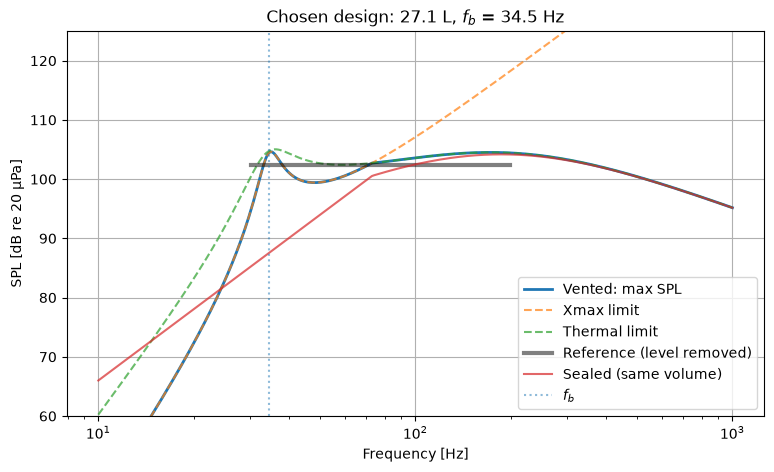

In [31]:
tolerance_db = 2.2   # accepted RMS error

chosen = min((d for d in designs if d.error <= tolerance_db), key=lambda d: d.volume)

print(f"Volume:           {1e3 * chosen.volume:.1f} L   (Vas = {1e3 * driver.Vas():.1f} L)")
print(f"Tuning fb:        {chosen.fb:.1f} Hz   (Fs = {driver.Fs:.1f} Hz)")
print(f"Vent radius:      {1e2 * chosen.vent.vent_radius:.2f} cm")
print(f"Vent length T:    {1e2 * chosen.vent.vent_length:.1f} cm")
print(f"RMS error:        {chosen.error:.2f} dB")

curve = chosen.curve
reference = np.full_like(freqs, reference_db)
offset = np.mean(curve.spl[in_band] - reference[in_band])

sealed_chosen = max_spl_curve(sealed_system(driver, chosen.volume), freqs, distance)

plt.figure()
plt.semilogx(freqs, curve.spl, linewidth=2, label="Vented: max SPL")
plt.semilogx(freqs, curve.spl_excursion_limited, "--", alpha=0.7, label="Xmax limit")
plt.semilogx(freqs, curve.spl_voltage_limited, "--", alpha=0.7, label="Thermal limit")
plt.semilogx(freqs[in_band], reference[in_band] + offset, "k", linewidth=3, alpha=0.5, label="Reference (level removed)")
plt.semilogx(freqs, sealed_chosen.spl, alpha=0.7, label="Sealed (same volume)")
plt.axvline(chosen.fb, linestyle=":", alpha=0.5, label="$f_b$")
plt.ylim(60, 125)
plt.xlabel("Frequency [Hz]")
plt.ylabel("SPL [dB re 20 µPa]")
plt.title(f"Chosen design: {1e3 * chosen.volume:.1f} L, $f_b$ = {chosen.fb:.1f} Hz")
plt.legend()
plt.show()

# Step 5 — Check with the real `VentedBox`

The design is built as an actual `VentedBox` with the derived radius and length. The max-SPL curve and the constraints are recomputed from it: the tuning, the SPL curve, the peak vent air speed and the cone excursion at the max-SPL drive.

In [32]:
final_box = VentedBox(
    chosen.volume,
    chosen.vent.vent_radius,
    chosen.vent.vent_length,
    Ql=Ql,
)
final = LoudspeakerSystem(driver, final_box, radiation=MonopoleRadiation())
final_curve = max_spl_curve(final, freqs, distance)

response_1v = final.solve(freqs, voltage=1.0, distance=distance)
vent_speed = np.abs(response_1v.vent_velocity) * final_curve.voltage
excursion_peak = np.sqrt(2) * np.abs(response_1v.displacement) * final_curve.voltage

print(f"fb from the box:               {final_box.tuning_frequency():.2f} Hz (design: {chosen.fb:.2f} Hz)")
print(f"Max |SPL difference|:          {np.max(np.abs(final_curve.spl - chosen.curve.spl)):.1e} dB")
print(f"Peak vent air speed:           {vent_speed.max():.2f} m/s (limit {limits.vent_velocity:.1f} m/s)")
print(f"Peak cone excursion:           {1e3 * excursion_peak.max():.2f} mm (Xmax {1e3 * driver.Xmax:.1f} mm)")
print(f"Max drive voltage:             {final_curve.voltage.max():.1f} V RMS")

fb from the box:               34.49 Hz (design: 34.49 Hz)
Max |SPL difference|:          2.8e-14 dB
Peak vent air speed:           17.00 m/s (limit 17.0 m/s)
Peak cone excursion:           6.00 mm (Xmax 6.0 mm)
Max drive voltage:             18.4 V RMS


# Step 6 — A smaller box: tuning and $f_3$ limits

The 27 L result above is large for two reasons. The design is sized for the full thermal drive (about 18 V, 100 W), and at that level the 17 m/s port-speed limit forces a wide, long vent. And the reference match alone does not ask for a small box.

This step changes the problem:

- **Tuning:** $f_b \le 40$ Hz.
- **Cutoff:** $f_3 \le 38$ Hz. Here $f_3$ is the classical small-signal value: the highest frequency below 100–200 Hz where the 1 V response is 3 dB under its mean level in that range.
- **Drive cap:** a cap on the RMS drive voltage replaces the thermal limit when it is lower. The vent is sized for the loudest drive you actually plan to use.
- **Selection:** the smallest volume for which some tuning in 20–$f_{b,max}$ Hz meets $f_3$ and the vent limits. Among those tunings, the one with the smallest band error.

The first cell shows how the smallest feasible volume depends on the voltage cap.

In [33]:
fb_max = 40.0         # Hz
f3_max = 38.0         # Hz
closed_volume = 3.7e-3  # m^3, the sealed box to compare with

volumes_small = np.geomspace(4e-3, 30e-3, 80)
caps = [2.83, 5.0, 10.0, 14.0, None]   # V RMS; None keeps only the thermal limit


def smallest_design(cap):
    cap_settings = {**settings, "limits": replace(limits, max_voltage=cap)}
    sweep = volume_sweep(driver, volumes_small, fb_bounds=(20.0, fb_max), max_f3=f3_max, **cap_settings)
    feasible_designs = [d for d in sweep if d is not None]
    return feasible_designs[0] if feasible_designs else None


for cap in caps:
    design = smallest_design(cap)
    label = "thermal" if cap is None else f"{cap:.2f} V"
    if design is None:
        print(f"cap {label:>8}: no feasible design")
        continue
    print(
        f"cap {label:>8}: V = {1e3 * design.volume:5.2f} L, fb = {design.fb:4.1f} Hz, f3 = {design.f3:4.1f} Hz, "
        f"error = {design.error:4.2f} dB, a_v = {1e2 * design.vent.vent_radius:4.2f} cm, T = {1e2 * design.vent.vent_length:5.1f} cm"
    )

cap   2.83 V: V = 11.68 L, fb = 37.3 Hz, f3 = 38.0 Hz, error = 1.85 dB, a_v = 1.50 cm, T =  11.7 cm
cap   5.00 V: V = 11.68 L, fb = 37.3 Hz, f3 = 38.0 Hz, error = 1.85 dB, a_v = 1.66 cm, T =  14.5 cm
cap  10.00 V: V = 11.68 L, fb = 37.3 Hz, f3 = 38.0 Hz, error = 1.85 dB, a_v = 2.35 cm, T =  29.9 cm
cap  14.00 V: V = 11.98 L, fb = 38.4 Hz, f3 = 37.8 Hz, error = 2.38 dB, a_v = 2.82 cm, T =  40.0 cm
cap  thermal: V = 19.45 L, fb = 39.8 Hz, f3 = 35.4 Hz, error = 3.46 dB, a_v = 3.76 cm, T =  40.0 cm


With a modest cap the volume is set by the $f_3$ target alone, so the vent limits stop mattering. A higher cap makes the vent speed limit the binding constraint instead. The next cells use a cap of 10 V RMS and show the profile over volume.

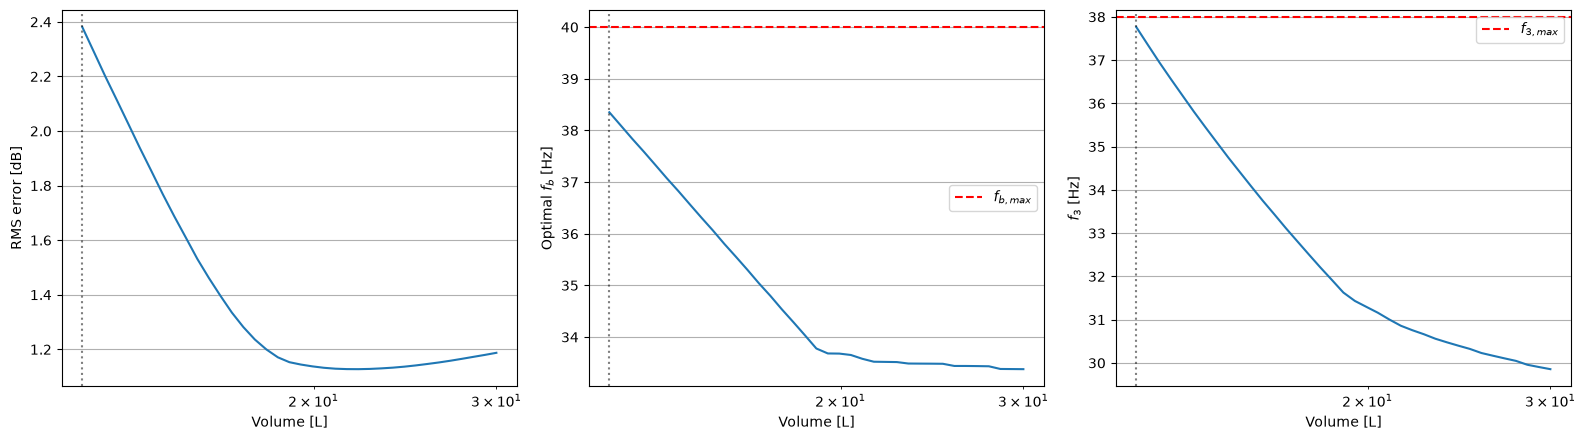

Smallest feasible volume: 11.98 L  (3.2x the 3.7 L sealed box)
Tuning fb:                38.4 Hz
f3:                       37.8 Hz
Vent radius:              2.82 cm
Vent length T:            40.0 cm
RMS error:                2.38 dB


In [37]:
voltage_cap = 14.0   # V RMS
small_settings = {**settings, "limits": replace(limits, max_voltage=voltage_cap)}

small_sweep = volume_sweep(driver, volumes_small, fb_bounds=(20.0, fb_max), max_f3=f3_max, **small_settings)
small_designs = [d for d in small_sweep if d is not None]
smallest = small_designs[0]

sv = np.array([d.volume for d in small_designs])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].semilogx(1e3 * sv, [d.error for d in small_designs])
axes[0].set_ylabel("RMS error [dB]")

axes[1].semilogx(1e3 * sv, [d.fb for d in small_designs])
axes[1].axhline(fb_max, color="r", linestyle="--", label="$f_{b,max}$")
axes[1].set_ylabel("Optimal $f_b$ [Hz]")
axes[1].legend()

axes[2].semilogx(1e3 * sv, [d.f3 for d in small_designs])
axes[2].axhline(f3_max, color="r", linestyle="--", label="$f_{3,max}$")
axes[2].set_ylabel("$f_3$ [Hz]")
axes[2].legend()

for ax in axes:
    ax.axvline(1e3 * smallest.volume, color="k", linestyle=":", alpha=0.5)
    ax.set_xlabel("Volume [L]")

fig.tight_layout()
plt.show()

print(f"Smallest feasible volume: {1e3 * smallest.volume:.2f} L  ({smallest.volume / closed_volume:.1f}x the {1e3 * closed_volume:.1f} L sealed box)")
print(f"Tuning fb:                {smallest.fb:.1f} Hz")
print(f"f3:                       {smallest.f3:.1f} Hz")
print(f"Vent radius:              {1e2 * smallest.vent.vent_radius:.2f} cm")
print(f"Vent length T:            {1e2 * smallest.vent.vent_length:.1f} cm")
print(f"RMS error:                {smallest.error:.2f} dB")

## Compared with the sealed box

The vented design against the sealed box of the volume in `closed_volume`: max SPL under the same drive cap, and the small-signal response at 1 V (normalised to its 100–200 Hz mean, with $f_3$ marked).

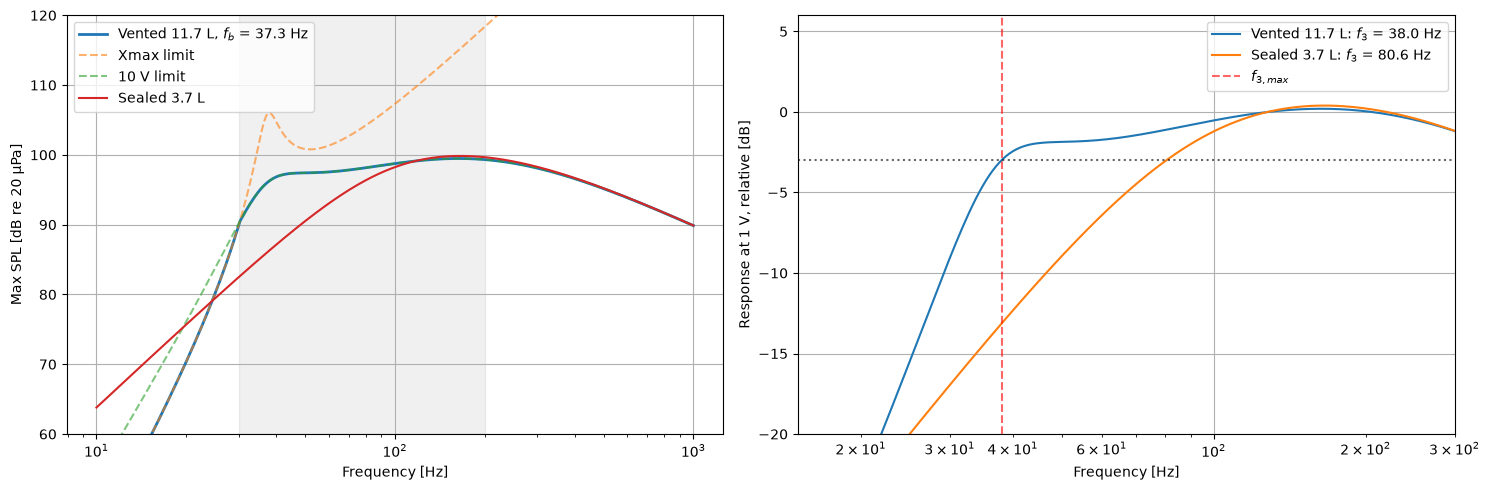

In [35]:
closed_curve = max_spl_curve(sealed_system(driver, closed_volume), freqs, distance, max_voltage=voltage_cap)
small_curve = smallest.curve

ref_band = (100.0, 200.0)
in_ref = (freqs >= ref_band[0]) & (freqs <= ref_band[1])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].semilogx(freqs, small_curve.spl, linewidth=2, label=f"Vented {1e3 * smallest.volume:.1f} L, $f_b$ = {smallest.fb:.1f} Hz")
axes[0].semilogx(freqs, small_curve.spl_excursion_limited, "--", alpha=0.6, label="Xmax limit")
axes[0].semilogx(freqs, small_curve.spl_voltage_limited, "--", alpha=0.6, label=f"{voltage_cap:.0f} V limit")
axes[0].semilogx(freqs, closed_curve.spl, label=f"Sealed {1e3 * closed_volume:.1f} L")
axes[0].axvspan(*band, color="k", alpha=0.06)
axes[0].set_ylim(60, 120)
axes[0].set_ylabel("Max SPL [dB re 20 µPa]")
axes[0].legend()

for label, spl_1v in (
    (f"Vented {1e3 * smallest.volume:.1f} L", small_curve.spl_per_volt),
    (f"Sealed {1e3 * closed_volume:.1f} L", closed_curve.spl_per_volt),
):
    level = spl_1v - np.mean(spl_1v[in_ref])
    axes[1].semilogx(freqs, level, label=f"{label}: $f_3$ = {f3_frequency(freqs, spl_1v):.1f} Hz")
axes[1].axhline(-3, color="k", linestyle=":", alpha=0.6)
axes[1].axvline(f3_max, color="r", linestyle="--", alpha=0.6, label="$f_{3,max}$")
axes[1].set_xlim(15, 300)
axes[1].set_ylim(-20, 6)
axes[1].set_ylabel("Response at 1 V, relative [dB]")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Frequency [Hz]")

fig.tight_layout()
plt.show()

## Check with the real `VentedBox`

The same check as in Step 5, for the smaller design and with the voltage cap applied.

In [36]:
small_box = VentedBox(
    smallest.volume,
    smallest.vent.vent_radius,
    smallest.vent.vent_length,
    Ql=Ql,
)
small_system = LoudspeakerSystem(driver, small_box, radiation=MonopoleRadiation())
check_curve = max_spl_curve(small_system, freqs, distance, max_voltage=voltage_cap)

check_1v = small_system.solve(freqs, voltage=1.0, distance=distance)
check_vent_speed = np.abs(check_1v.vent_velocity) * check_curve.voltage
check_excursion = np.sqrt(2) * np.abs(check_1v.displacement) * check_curve.voltage

print(f"fb from the box:               {small_box.tuning_frequency():.2f} Hz (limit {fb_max:.1f} Hz)")
print(f"f3 from the box:               {f3_frequency(freqs, check_curve.spl_per_volt):.2f} Hz (limit {f3_max:.1f} Hz)")
print(f"Max |SPL difference|:          {np.max(np.abs(check_curve.spl - smallest.curve.spl)):.1e} dB")
print(f"Peak vent air speed:           {check_vent_speed.max():.2f} m/s (limit {limits.vent_velocity:.1f} m/s)")
print(f"Peak cone excursion:           {1e3 * check_excursion.max():.2f} mm (Xmax {1e3 * driver.Xmax:.1f} mm)")
print(f"Max drive voltage:             {check_curve.voltage.max():.1f} V RMS (cap {voltage_cap:.1f} V)")

fb from the box:               37.32 Hz (limit 40.0 Hz)
f3 from the box:               38.00 Hz (limit 38.0 Hz)
Max |SPL difference|:          0.0e+00 dB
Peak vent air speed:           17.00 m/s (limit 17.0 m/s)
Peak cone excursion:           6.00 mm (Xmax 6.0 mm)
Max drive voltage:             10.0 V RMS (cap 10.0 V)
